# V15 — Port-specific Autoencoder ensemble testing
Class-wise detection, confusion matrices, misclassifications and reconstruction-error histograms.


**V15 port-specific testing:** uses the saved V15 ensemble and calibrated thresholds. The final latent-space cell loads its own test inputs and fits PCA on BENIGN training representations.


In [21]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import joblib
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

PROJECT_ROOT=Path.cwd().resolve()
if PROJECT_ROOT.name=='notebooks': PROJECT_ROOT=PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0,str(PROJECT_ROOT))
from autoencoder_v15_common import VERSION, validate_frame, transform, reconstruction_mse, thresholds_for_ports
DATA_DIR=PROJECT_ROOT/'data'/'processed'/'unknown_detection'
MODEL_DIR=PROJECT_ROOT/'saved-models'/f'autoencoder_{VERSION}'
RESULTS_DIR=PROJECT_ROOT/'outputs'/'results'/f'autoencoder_{VERSION}'
RESULTS_DIR.mkdir(parents=True,exist_ok=True)
selection=json.loads((MODEL_DIR/f'autoencoder_{VERSION}_selection.json').read_text())
calibration=json.loads((MODEL_DIR/selection['calibration_file']).read_text())
prep=joblib.load(MODEL_DIR/f'autoencoder_{VERSION}_preprocessing.joblib')
models=[keras.models.load_model(MODEL_DIR/f) for f in selection['model_files']]
print('Loaded models:',len(models),'global threshold:',calibration['global_threshold'])

Loaded models: 3 global threshold: 0.017142509448652452


## Class-wise detection, misclassification, and confusion matrices
Each unknown attack is evaluated as anomaly vs BENIGN. The Autoencoder does not predict attack subtypes.



DATASET: balanced_unknown_test.csv
Actual class distribution: {'BENIGN': 6448, 'FTP-Patator': 3972, 'DoS Slowhttptest': 1740, 'Botnet': 736}
Accuracy=0.9142 | Precision=0.9597 | Recall=0.8648 | F1=0.9098
TN=6214 FP=234 FN=872 TP=5576 | FPR=0.0363
              precision    recall  f1-score   support

      BENIGN       0.88      0.96      0.92      6448
     UNKNOWN       0.96      0.86      0.91      6448

    accuracy                           0.91     12896
   macro avg       0.92      0.91      0.91     12896
weighted avg       0.92      0.91      0.91     12896



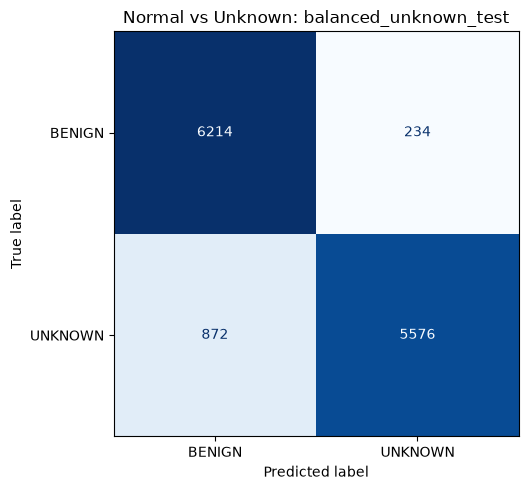

Class-wise correct / misclassified counts:
                  dataset     actual_class  samples  correctly_classified  misclassified  class_recall
balanced_unknown_test.csv           BENIGN     6448                  6214            234      0.963710
balanced_unknown_test.csv           Botnet      736                    44            692      0.059783
balanced_unknown_test.csv DoS Slowhttptest     1740                  1575            165      0.905172
balanced_unknown_test.csv      FTP-Patator     3972                  3957             15      0.996224
Misclassified records: 1106

DATASET: balanced_botnet_test.csv
Actual class distribution: {'Botnet': 736, 'BENIGN': 736}
Accuracy=0.5109 | Precision=0.6111 | Recall=0.0598 | F1=0.1089
TN=708 FP=28 FN=692 TP=44 | FPR=0.0380
              precision    recall  f1-score   support

      BENIGN       0.51      0.96      0.66       736
     UNKNOWN       0.61      0.06      0.11       736

    accuracy                           0.51      1472
 

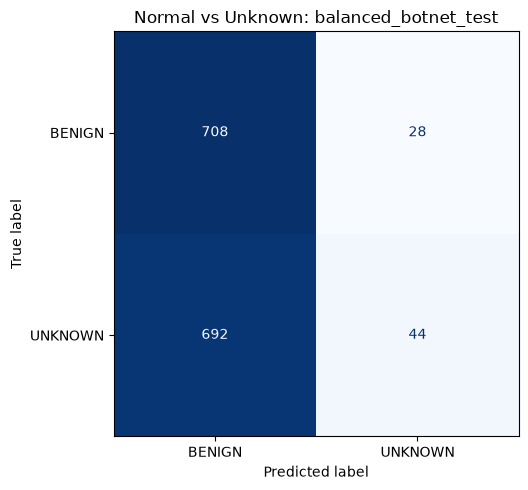

Class-wise correct / misclassified counts:
                 dataset actual_class  samples  correctly_classified  misclassified  class_recall
balanced_botnet_test.csv       BENIGN      736                   708             28      0.961957
balanced_botnet_test.csv       Botnet      736                    44            692      0.059783
Misclassified records: 720

DATASET: balanced_dos_slowhttptest_test.csv
Actual class distribution: {'DoS Slowhttptest': 1740, 'BENIGN': 1740}
Accuracy=0.9336 | Precision=0.9598 | Recall=0.9052 | F1=0.9317
TN=1674 FP=66 FN=165 TP=1575 | FPR=0.0379
              precision    recall  f1-score   support

      BENIGN       0.91      0.96      0.94      1740
     UNKNOWN       0.96      0.91      0.93      1740

    accuracy                           0.93      3480
   macro avg       0.94      0.93      0.93      3480
weighted avg       0.94      0.93      0.93      3480



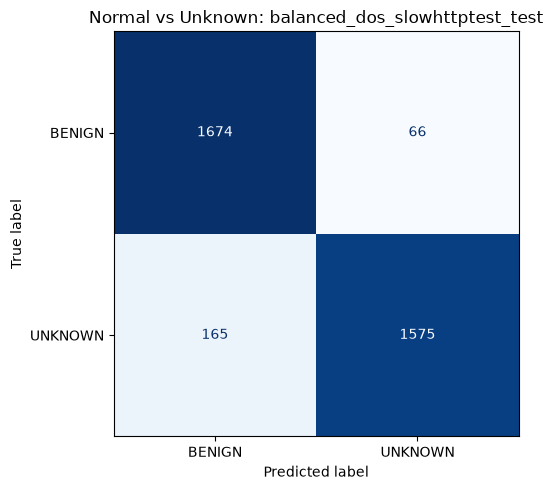

Class-wise correct / misclassified counts:
                           dataset     actual_class  samples  correctly_classified  misclassified  class_recall
balanced_dos_slowhttptest_test.csv           BENIGN     1740                  1674             66      0.962069
balanced_dos_slowhttptest_test.csv DoS Slowhttptest     1740                  1575            165      0.905172
Misclassified records: 231

DATASET: balanced_ftp_patator_test.csv
Actual class distribution: {'BENIGN': 3972, 'FTP-Patator': 3972}
Accuracy=0.9805 | Precision=0.9658 | Recall=0.9962 | F1=0.9808
TN=3832 FP=140 FN=15 TP=3957 | FPR=0.0352
              precision    recall  f1-score   support

      BENIGN       1.00      0.96      0.98      3972
     UNKNOWN       0.97      1.00      0.98      3972

    accuracy                           0.98      7944
   macro avg       0.98      0.98      0.98      7944
weighted avg       0.98      0.98      0.98      7944



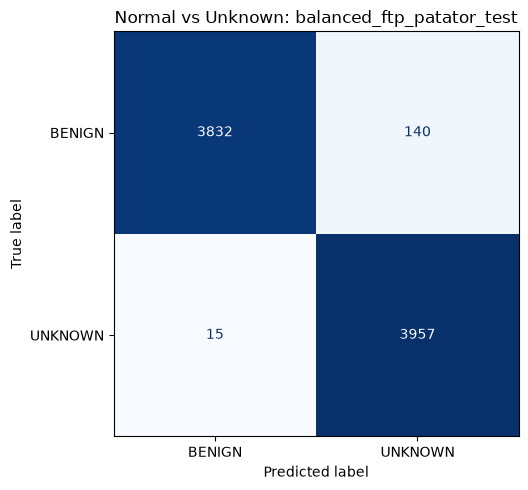

Class-wise correct / misclassified counts:
                      dataset actual_class  samples  correctly_classified  misclassified  class_recall
balanced_ftp_patator_test.csv       BENIGN     3972                  3832            140      0.964753
balanced_ftp_patator_test.csv  FTP-Patator     3972                  3957             15      0.996224
Misclassified records: 155

=== FINAL DATASET SUMMARY ===
                           dataset  total  normal  attacks  accuracy  precision   recall       f1  false_positive_rate   TN  FP  FN   TP  roc_auc  average_precision
         balanced_unknown_test.csv  12896    6448     6448  0.914237   0.959725 0.864764 0.909773             0.036290 6214 234 872 5576 0.952719           0.929009
          balanced_botnet_test.csv   1472     736      736  0.510870   0.611111 0.059783 0.108911             0.038043  708  28 692   44 0.760744           0.656489
balanced_dos_slowhttptest_test.csv   3480    1740     1740  0.933621   0.959781 0.905172 0.9316

In [22]:
# Class-wise detection metrics and misclassifications using the saved V15 ensemble.
# Each attack is evaluated as BENIGN (0) versus that unknown attack (1).
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, classification_report)

TEST_FILES = [DATA_DIR / 'balanced_unknown_test.csv'] + sorted(
    p for p in DATA_DIR.glob('balanced_*_test.csv') if p.name != 'balanced_unknown_test.csv'
)
TEST_FILES = [p for p in TEST_FILES if p.exists()]
if not TEST_FILES:
    raise FileNotFoundError('No balanced test CSVs found. Run preprocessing notebook 01 first.')

summary_rows = []
class_rows = []
misclassified_rows = []

for test_file in TEST_FILES:
    frame, features = validate_frame(pd.read_csv(test_file, low_memory=False), test_file.name)
    scaled = transform(features, prep)
    anomaly_scores = np.asarray(reconstruction_mse(models, scaled)).reshape(-1)
    port_col = next((c for c in ('Destination Port', 'Dst Port') if c in frame.columns), None)
    if port_col:
        ports = pd.to_numeric(frame[port_col], errors='coerce').to_numpy()
        thresholds = np.asarray(thresholds_for_ports(ports, calibration)).reshape(-1)
    else:
        raise ValueError('Missing Dst Port in test CSV. Re-run V15 Notebook 01.')

    actual = frame['Label'].ne('BENIGN').astype(int).to_numpy()
    predicted = (anomaly_scores > thresholds).astype(int)
    cm = confusion_matrix(actual, predicted, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    accuracy = accuracy_score(actual, predicted)
    precision = precision_score(actual, predicted, zero_division=0)
    recall = recall_score(actual, predicted, zero_division=0)
    f1 = f1_score(actual, predicted, zero_division=0)
    fpr = fp / (fp + tn) if (fp + tn) else float('nan')
    auc = roc_auc_score(actual, anomaly_scores) if len(np.unique(actual)) == 2 else float('nan')
    ap = average_precision_score(actual, anomaly_scores) if len(np.unique(actual)) == 2 else float('nan')
    summary_rows.append(dict(dataset=test_file.name, total=len(frame), normal=int((actual == 0).sum()),
                             attacks=int((actual == 1).sum()), accuracy=accuracy, precision=precision,
                             recall=recall, f1=f1, false_positive_rate=fpr,
                             TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp), roc_auc=auc, average_precision=ap))

    print('\n' + '=' * 75)
    print('DATASET:', test_file.name)
    print('Actual class distribution:', frame['Label'].value_counts().to_dict())
    print(f'Accuracy={accuracy:.4f} | Precision={precision:.4f} | Recall={recall:.4f} | F1={f1:.4f}')
    print(f'TN={tn} FP={fp} FN={fn} TP={tp} | FPR={fpr:.4f}')
    print(classification_report(actual, predicted, labels=[0, 1],
                                target_names=['BENIGN', 'UNKNOWN'], zero_division=0))
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=['BENIGN', 'UNKNOWN']).plot(
        ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title('Normal vs Unknown: ' + test_file.stem)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{test_file.stem}_confusion_matrix.png', dpi=150)
    plt.show()
    plt.close(fig)

    detail = pd.DataFrame({'actual_label': frame['Label'].astype(str).to_numpy(),
                           'actual_binary': actual, 'predicted_binary': predicted,
                           'predicted_label': np.where(predicted == 1, 'UNKNOWN', 'BENIGN'),
                           'anomaly_score': anomaly_scores, 'threshold': thresholds})
    detail['correct'] = detail['actual_binary'].eq(detail['predicted_binary'])
    detail.to_csv(RESULTS_DIR / f'{test_file.stem}_predictions.csv', index=False)
    errors = detail.loc[~detail['correct']].copy()
    errors.insert(0, 'dataset', test_file.name)
    misclassified_rows.append(errors)
    errors.to_csv(RESULTS_DIR / f'{test_file.stem}_misclassified.csv', index=False)

    # Class-wise means attack-specific detection rate, not predicted attack identity.
    for label, group in detail.groupby('actual_label', sort=True):
        detected = int(group['correct'].sum())
        missed = len(group) - detected
        class_rows.append(dict(dataset=test_file.name, actual_class=label,
                               samples=len(group), correctly_classified=detected,
                               misclassified=missed, class_recall=detected / len(group)))
    print('Class-wise correct / misclassified counts:')
    print(pd.DataFrame([r for r in class_rows if r['dataset'] == test_file.name]).to_string(index=False))
    print('Misclassified records:', len(errors))

summary_df = pd.DataFrame(summary_rows)
classwise_df = pd.DataFrame(class_rows)
summary_df.to_csv(RESULTS_DIR / 'test_summary.csv', index=False)
classwise_df.to_csv(RESULTS_DIR / 'classwise_metrics.csv', index=False)
if misclassified_rows:
    pd.concat(misclassified_rows, ignore_index=True).to_csv(
        RESULTS_DIR / 'all_misclassifications.csv', index=False)
print('\n=== FINAL DATASET SUMMARY ===')
print(summary_df.to_string(index=False))
print('\n=== CLASS-WISE DETECTION SUMMARY ===')
print(classwise_df.to_string(index=False))
print('\nSaved metrics, confusion-matrix PNGs and misclassification CSVs to:', RESULTS_DIR)


In [23]:
# Separate false-positive rate on the full held-out BENIGN test.
p=DATA_DIR/'normal_test.csv'
if p.exists():
    df,x=validate_frame(pd.read_csv(p,low_memory=False),'normal_test',benign_only=True)
    scores=reconstruction_mse(models,transform(x,prep))
    port_col=next((c for c in ('Destination Port','Dst Port') if c in df.columns),None)
    ports=pd.to_numeric(df[port_col],errors='coerce').fillna(0).astype(int).to_numpy() if port_col else np.zeros(len(df),dtype=int)
    thresholds=thresholds_for_ports(ports,calibration) if port_col else np.full(len(df),calibration['global_threshold'])
    print('Normal test false-positive rate:',float(np.mean(scores>thresholds)))

Normal test false-positive rate: 0.031896969019958296


Global threshold: 0.017142509448652452

Records by class:
actual_label
BENIGN              6448
FTP-Patator         3972
DoS Slowhttptest    1740
Botnet               736
Name: count, dtype: int64


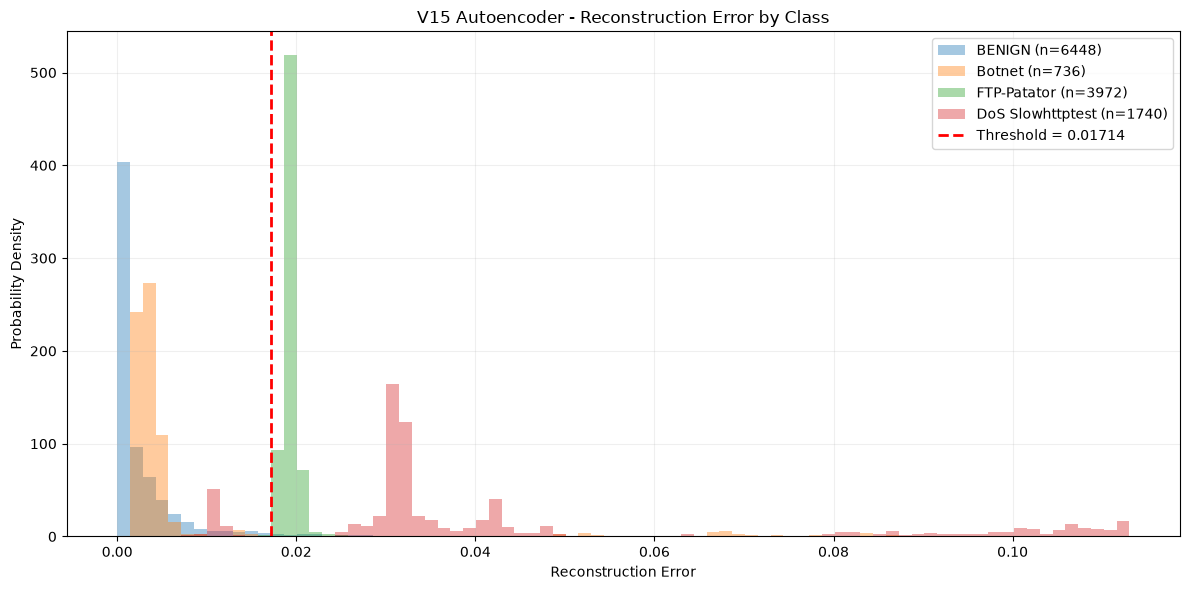

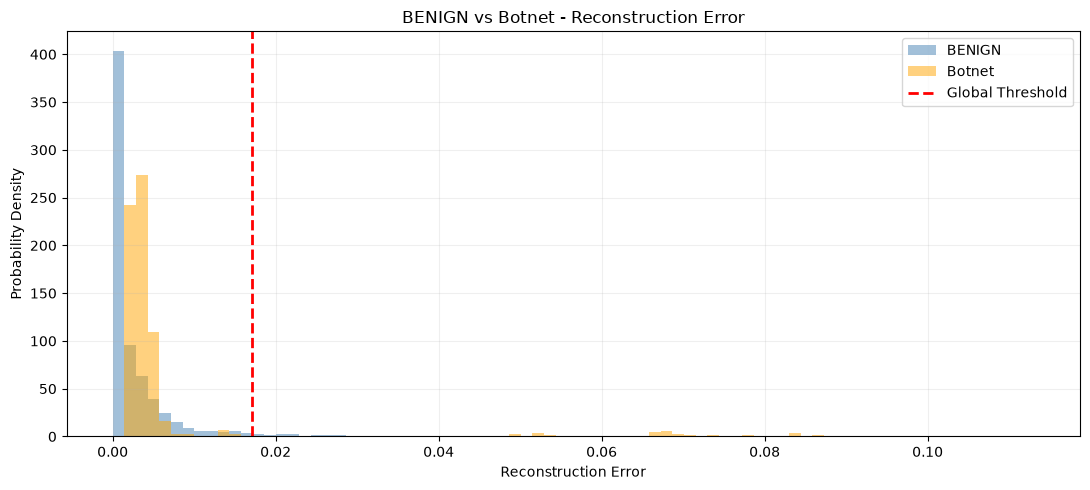


Reconstruction Error Summary:


,count,mean,median,std,min,max,Above Threshold (%)
actual_label,,,,,,,
BENIGN,6448,0.003190,0.000562,0.008421,0.000014,0.186386,3.287841
Botnet,736,0.007423,0.003345,0.015429,0.002020,0.087070,5.978261
DoS Slowhttptest,1740,0.049248,0.032068,0.033569,0.002685,0.126954,90.747126
FTP-Patator,3972,0.019335,0.019249,0.001139,0.009961,0.034677,99.622356


In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD EXISTING V15 TEST RESULTS
# ============================================================

predictions_file = (
    RESULTS_DIR / "balanced_unknown_test_predictions.csv"
)

df = pd.read_csv(predictions_file)

# Your existing notebook saves the label as actual_label
LABEL_COL = "actual_label"
SCORE_COL = "anomaly_score"

classes = [
    "BENIGN",
    "Botnet",
    "FTP-Patator",
    "DoS Slowhttptest"
]

df = df[df[LABEL_COL].isin(classes)].copy()

df[SCORE_COL] = pd.to_numeric(
    df[SCORE_COL],
    errors="coerce"
)

df = df.dropna(subset=[SCORE_COL])

threshold = float(calibration["global_threshold"])

print("Global threshold:", threshold)
print("\nRecords by class:")
print(df[LABEL_COL].value_counts())

# ============================================================
# 2. COMMON HISTOGRAM BINS
# ============================================================

# Limit the visible range to reduce distortion from
# extreme reconstruction errors.
upper = max(
    df[SCORE_COL].quantile(0.99),
    threshold * 1.1
)

bins = np.linspace(
    min(0, df[SCORE_COL].min()),
    upper,
    80
)

# ============================================================
# 3. ALL CLASSES HISTOGRAM
# ============================================================

plt.figure(figsize=(12, 6))

for attack in classes:

    scores = df.loc[
        df[LABEL_COL] == attack,
        SCORE_COL
    ]

    if scores.empty:
        continue

    plt.hist(
        scores,
        bins=bins,
        density=True,
        alpha=0.4,
        label=f"{attack} (n={len(scores)})"
    )

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {threshold:.5f}"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Probability Density")
plt.title("V15 Autoencoder - Reconstruction Error by Class")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ============================================================
# 4. BENIGN VS BOTNET HISTOGRAM
# ============================================================

plt.figure(figsize=(11, 5))

for attack, color in [
    ("BENIGN", "steelblue"),
    ("Botnet", "orange")
]:

    scores = df.loc[
        df[LABEL_COL] == attack,
        SCORE_COL
    ]

    plt.hist(
        scores,
        bins=bins,
        density=True,
        alpha=0.5,
        color=color,
        label=attack
    )

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Global Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Probability Density")
plt.title("BENIGN vs Botnet - Reconstruction Error")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ============================================================
# 5. CLASS-WISE ERROR STATISTICS
# ============================================================

summary = df.groupby(LABEL_COL)[SCORE_COL].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

summary["Above Threshold (%)"] = (
    df.groupby(LABEL_COL)[SCORE_COL]
    .apply(lambda x: (x > threshold).mean() * 100)
)

print("\nReconstruction Error Summary:")
display(summary.round(6))


BENIGN training latent shape: (20000, 36)
Test latent shape: (12896, 36)


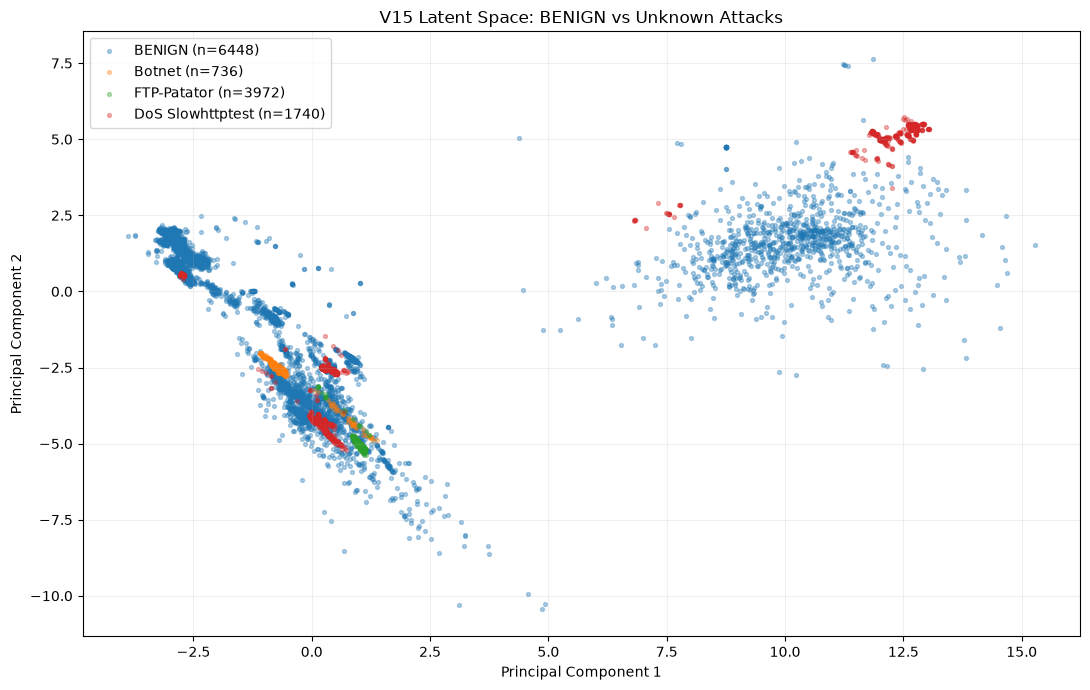

BENIGN-training PCA explained variance ratio: [0.5630863  0.15413481]
Saved: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\outputs\results\autoencoder_v15\v15_latent_pca.png
Note: PCA is a visualization, not proof of class separability in full latent space.


In [25]:
# V15 latent-space analysis — uses the same saved preprocessing and models.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

TEST_FILE = DATA_DIR / "balanced_unknown_test.csv"
TRAIN_FILE = DATA_DIR / "normal_train.csv"
if not TEST_FILE.exists() or not TRAIN_FILE.exists():
    raise FileNotFoundError("Run Notebook 01 to create the normal and balanced test CSVs first.")

# validate_frame and transform come from the V15 common module already imported above.
test_df, test_features = validate_frame(pd.read_csv(TEST_FILE, low_memory=False), "balanced_unknown_test")
X_test = transform(test_features, prep)

# Fit PCA visualization on a reproducible subset of BENIGN training traffic only.
train_raw = pd.read_csv(TRAIN_FILE, low_memory=False)
train_subset = train_raw.sample(n=min(20000, len(train_raw)), random_state=42)
train_df, train_features = validate_frame(train_subset, "normal_train_latent", benign_only=True)
X_train_latent = transform(train_features, prep)

def extract_latent_vectors(model, X, bottleneck_dim=12):
    candidates = [layer for layer in model.layers
                  if getattr(layer, "units", None) == bottleneck_dim]
    if len(candidates) != 1:
        raise ValueError(f"Expected exactly one {bottleneck_dim}-unit bottleneck layer; found {len(candidates)}")
    encoder = keras.Model(inputs=model.inputs, outputs=candidates[0].output)
    return encoder.predict(X, verbose=0, batch_size=1024)

Z_train = np.concatenate([extract_latent_vectors(model, X_train_latent) for model in models], axis=1)
Z_test = np.concatenate([extract_latent_vectors(model, X_test) for model in models], axis=1)
assert len(Z_test) == len(test_df)
print("BENIGN training latent shape:", Z_train.shape)
print("Test latent shape:", Z_test.shape)

latent_scaler = StandardScaler().fit(Z_train)
train_latent_scaled = latent_scaler.transform(Z_train)
test_latent_scaled = latent_scaler.transform(Z_test)
pca = PCA(n_components=2, random_state=42).fit(train_latent_scaled)
coords = pca.transform(test_latent_scaled)
labels = test_df["Label"].astype(str).to_numpy()

fig, ax = plt.subplots(figsize=(11, 7))
for label in ["BENIGN", "Botnet", "FTP-Patator", "DoS Slowhttptest"]:
    mask = labels == label
    if mask.any():
        ax.scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.35,
                   label=f"{label} (n={mask.sum()})", rasterized=True)
ax.set(xlabel="Principal Component 1", ylabel="Principal Component 2",
       title="V15 Latent Space: BENIGN vs Unknown Attacks")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "v15_latent_pca.png", dpi=160)
plt.show()
print("BENIGN-training PCA explained variance ratio:", pca.explained_variance_ratio_)
print("Saved:", RESULTS_DIR / "v15_latent_pca.png")
print("Note: PCA is a visualization, not proof of class separability in full latent space.")


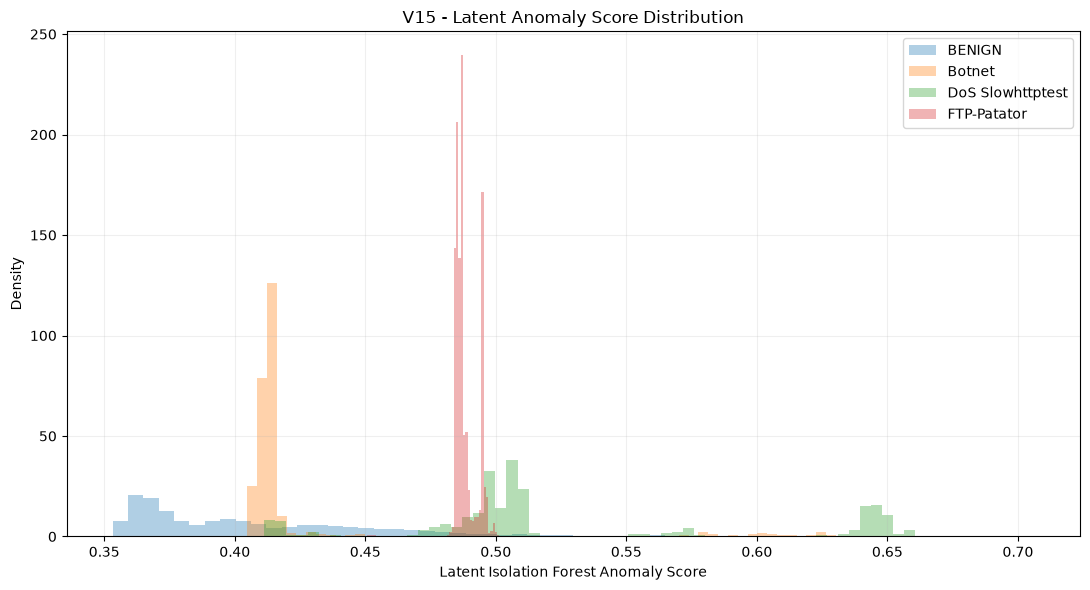


LATENT-SPACE SEPARATION RESULTS


,Attack,ROC-AUC,Mean Latent Score,Median Latent Score
0,Botnet,0.6381,0.4244,0.4130
1,DoS Slowhttptest,0.9229,0.5267,0.5049
2,FTP-Patator,0.9198,0.4882,0.4869


In [26]:

from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. FIT LATENT-SPACE DETECTOR ON BENIGN TRAINING ONLY
# ============================================================

detector = IsolationForest(
    n_estimators=200,
    max_samples=2048,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

detector.fit(train_latent_scaled)

# Higher score = more anomalous
train_scores = -detector.score_samples(train_latent_scaled)
test_scores = -detector.score_samples(test_latent_scaled)

# ============================================================
# 2. EXPLORATORY LATENT SCORE DISTRIBUTIONS
# ============================================================

labels = test_df["Label"].astype(str).to_numpy()

classes = [
    "BENIGN",
    "Botnet",
    "DoS Slowhttptest",
    "FTP-Patator"
]

fig, ax = plt.subplots(figsize=(11, 6))

for label in classes:
    scores = test_scores[labels == label]

    if len(scores):
        ax.hist(
            scores,
            bins=60,
            density=True,
            alpha=0.35,
            label=label
        )

ax.set_xlabel("Latent Isolation Forest Anomaly Score")
ax.set_ylabel("Density")
ax.set_title("V15 - Latent Anomaly Score Distribution")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ============================================================
# 3. CLASS-WISE SEPARATION
# ============================================================

rows = []

normal_mask = labels == "BENIGN"

for attack in classes[1:]:
    attack_mask = labels == attack

    selected = normal_mask | attack_mask

    actual = attack_mask[selected].astype(int)
    scores = test_scores[selected]

    auc = roc_auc_score(actual, scores)

    rows.append({
        "Attack": attack,
        "ROC-AUC": auc,
        "Mean Latent Score": test_scores[attack_mask].mean(),
        "Median Latent Score": np.median(
            test_scores[attack_mask]
        )
    })

summary = pd.DataFrame(rows)

print("\nLATENT-SPACE SEPARATION RESULTS")
display(summary.round(4))

summary.to_csv(
    RESULTS_DIR / "latent_separation_results.csv",
    index=False
)


## V15 — Feature-level reconstruction diagnostics
This section uses the **already-loaded** V15 ensemble and `X_test` from the earlier cells. No retraining or threshold tuning occurs. Class-wise AUC is **diagnostic only**: do not select feature weights or thresholds based on held-out attack labels.

Feature errors: (12896, 73)
Class counts: {'BENIGN': 6448, 'FTP-Patator': 3972, 'DoS Slowhttptest': 1740, 'Botnet': 736}

Top 15 features by diagnostic ROC-AUC: Botnet


,Attack,Feature,BENIGN mean error,Attack mean error,Error ratio,Single-feature ROC-AUC
18,Botnet,Flow IAT Max,0.0029,0.0179,6.1329,0.9709
27,Botnet,Bwd IAT Std,0.0029,0.0088,3.0412,0.9438
0,Botnet,Protocol,0.0019,0.0045,2.4079,0.9206
61,Botnet,Fwd Seg Size Min,0.0130,0.0318,2.4454,0.8994
43,Botnet,SYN Flag Count,0.0140,0.0254,1.8186,0.8940
54,Botnet,Subflow Fwd Packets,0.0003,0.0004,1.1389,0.8936
30,Botnet,Fwd PSH Flags,0.0041,0.0671,16.4573,0.8902
9,Botnet,Fwd Packet Length Std,0.0027,0.0044,1.6346,0.8741
72,Botnet,Total TCP Flow Time,0.0035,0.0047,1.3515,0.8741
23,Botnet,Fwd IAT Max,0.0008,0.0017,1.9822,0.8740


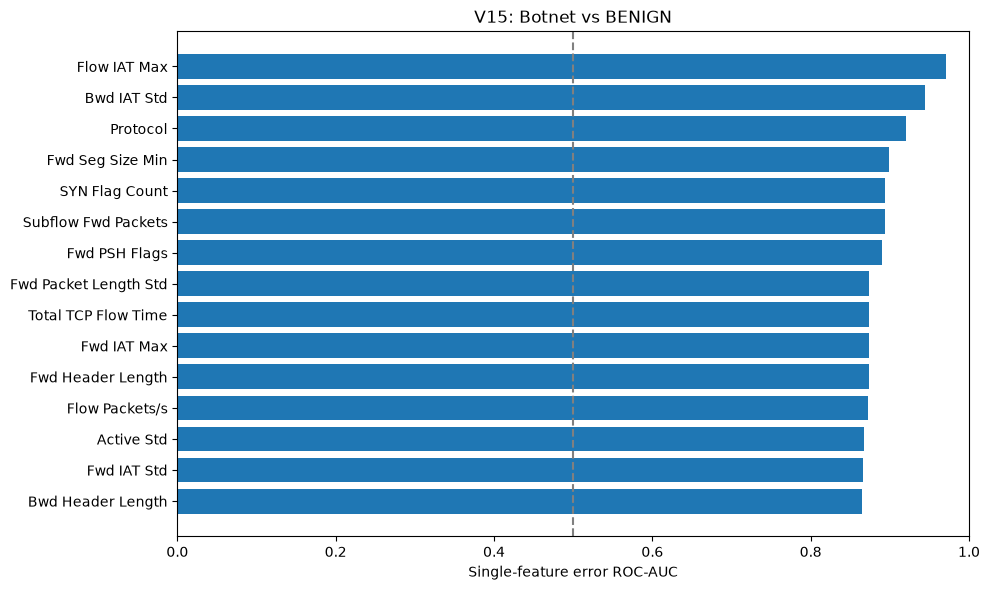


Top 15 features by diagnostic ROC-AUC: FTP-Patator


,Attack,Feature,BENIGN mean error,Attack mean error,Error ratio,Single-feature ROC-AUC
133,FTP-Patator,Fwd Act Data Pkts,0.0042,0.1281,30.8188,0.9972
104,FTP-Patator,Fwd RST Flags,0.0049,0.1575,31.9420,0.9956
117,FTP-Patator,RST Flag Count,0.0032,0.0747,23.3694,0.9930
105,FTP-Patator,Bwd RST Flags,0.0107,0.2424,22.5519,0.9911
125,FTP-Patator,Fwd Segment Size Avg,0.0008,0.0122,14.6867,0.9879
81,FTP-Patator,Fwd Packet Length Mean,0.0008,0.0111,14.0612,0.9871
126,FTP-Patator,Bwd Segment Size Avg,0.0008,0.0084,10.0995,0.9839
131,FTP-Patator,FWD Init Win Bytes,0.0036,0.0406,11.2777,0.9830
121,FTP-Patator,CWR Flag Count,0.0004,0.0001,0.2354,0.9824
85,FTP-Patator,Bwd Packet Length Mean,0.0008,0.0070,8.4638,0.9805


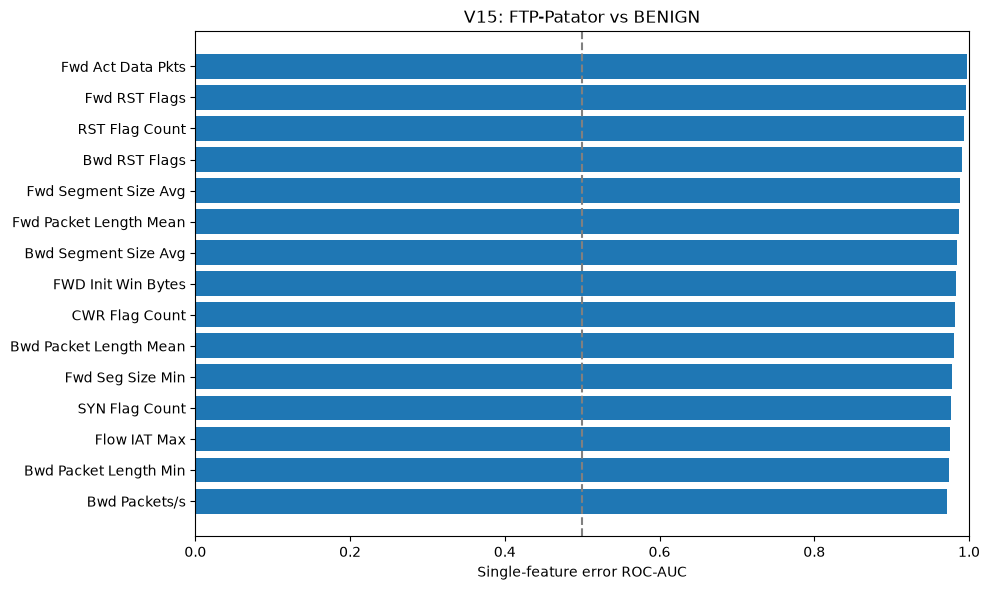


Top 15 features by diagnostic ROC-AUC: DoS Slowhttptest


,Attack,Feature,BENIGN mean error,Attack mean error,Error ratio,Single-feature ROC-AUC
182,DoS Slowhttptest,Bwd Packets/s,0.0036,0.0613,17.0156,0.9892
208,DoS Slowhttptest,Active Mean,0.0015,0.0417,28.4547,0.9884
161,DoS Slowhttptest,Flow Packets/s,0.0012,0.0252,21.2950,0.9880
210,DoS Slowhttptest,Active Max,0.0014,0.0325,23.1227,0.9866
192,DoS Slowhttptest,ACK Flag Count,0.0013,0.0204,15.9004,0.9856
181,DoS Slowhttptest,Fwd Packets/s,0.0015,0.0345,22.2762,0.9848
211,DoS Slowhttptest,Active Min,0.0028,0.0789,28.0015,0.9841
151,DoS Slowhttptest,Total Length of Bwd Packet,0.0016,0.0327,20.4712,0.9840
215,DoS Slowhttptest,Idle Min,0.0013,0.0315,24.8782,0.9826
212,DoS Slowhttptest,Idle Mean,0.0012,0.0324,26.7452,0.9810


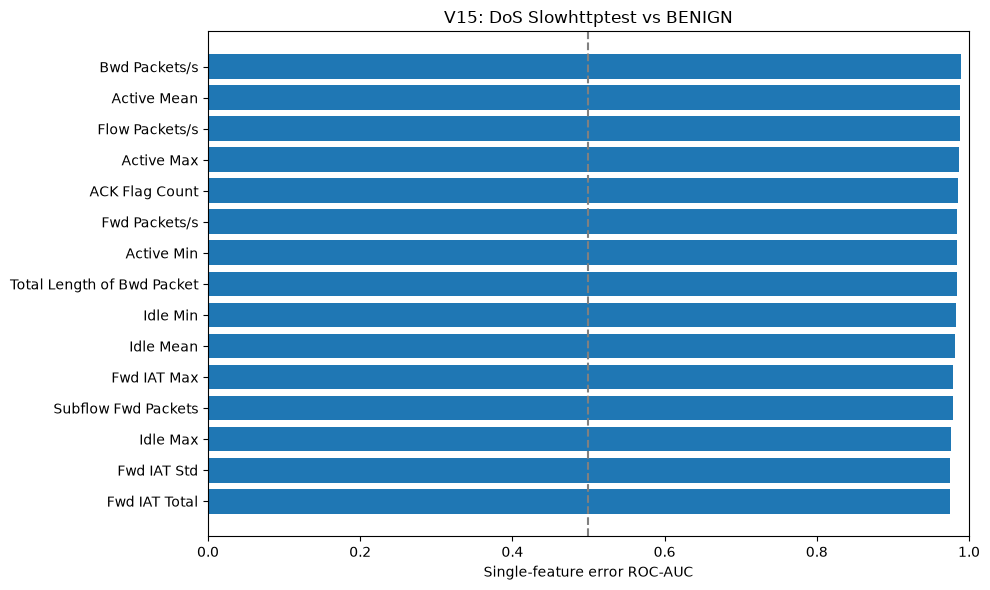

Saved: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\outputs\results\autoencoder_v15\v15_feature_error_comparison.csv


In [27]:
# Ensemble per-feature squared reconstruction error (same scaled inputs as V15)
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert len(models) == 3, "Expected V15 ensemble of three models"
assert len(X_test) == len(test_df), "Test features and labels are misaligned"
feature_names = list(prep["columns"])
assert X_test.shape[1] == len(feature_names)

# Batch predictions to limit peak RAM usage.
def per_feature_ensemble_errors(models, X, batch_size=1024):
    out = np.empty(X.shape, dtype=np.float32)
    for start in range(0, len(X), batch_size):
        stop = min(start + batch_size, len(X))
        batch = X[start:stop]
        squared = np.zeros(batch.shape, dtype=np.float64)
        for model in models:
            reconstructed = model.predict(batch, verbose=0, batch_size=batch_size)
            squared += (batch.astype(np.float64) - reconstructed.astype(np.float64)) ** 2
        out[start:stop] = (squared / len(models)).astype(np.float32)
    return out

feature_errors = per_feature_ensemble_errors(models, X_test)
labels = test_df["Label"].astype(str).to_numpy()
classes = ["BENIGN", "Botnet", "FTP-Patator", "DoS Slowhttptest"]
print("Feature errors:", feature_errors.shape)
print("Class counts:", pd.Series(labels).value_counts().to_dict())

# Compare mean feature errors, with ratio and single-feature ROC-AUC.
normal = feature_errors[labels == "BENIGN"]
if not len(normal):
    raise ValueError("Balanced test must contain BENIGN flows")
rows = []
for attack in classes[1:]:
    attacked = feature_errors[labels == attack]
    if not len(attacked):
        print("Skipping absent class:", attack)
        continue
    normal_mean = normal.mean(axis=0)
    attack_mean = attacked.mean(axis=0)
    actual = np.r_[np.zeros(len(normal)), np.ones(len(attacked))]
    for j, feature in enumerate(feature_names):
        scores = np.r_[normal[:, j], attacked[:, j]]
        rows.append({
            "Attack": attack, "Feature": feature,
            "BENIGN mean error": float(normal_mean[j]),
            "Attack mean error": float(attack_mean[j]),
            "Error ratio": float((attack_mean[j] + 1e-9) / (normal_mean[j] + 1e-9)),
            "Single-feature ROC-AUC": float(roc_auc_score(actual, scores))
        })
feature_summary = pd.DataFrame(rows)
feature_summary.to_csv(RESULTS_DIR / "v15_feature_error_comparison.csv", index=False)
for attack in feature_summary["Attack"].unique():
    top = (feature_summary[feature_summary["Attack"] == attack]
           .sort_values("Single-feature ROC-AUC", ascending=False).head(15))
    print("\nTop 15 features by diagnostic ROC-AUC:", attack)
    display(top.round(4))
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top["Feature"].iloc[::-1], top["Single-feature ROC-AUC"].iloc[::-1])
    ax.axvline(0.5, linestyle="--", color="gray", label="Chance")
    ax.set(xlabel="Single-feature error ROC-AUC", title=f"V15: {attack} vs BENIGN")
    ax.set_xlim(0, 1)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"v15_features_{attack.lower().replace(' ', '_').replace('-', '_')}.png", dpi=160)
    plt.show()
print("Saved:", RESULTS_DIR / "v15_feature_error_comparison.csv")

Attack,Botnet,DoS Slowhttptest,FTP-Patator
Score method,,,
Mean reconstruction MSE,0.7663,0.9867,0.9724
Top-1 feature MSE,0.7602,0.9687,0.9400
Top-10 feature MSE,0.7577,0.9819,0.9707
Top-3 feature MSE,0.7649,0.9737,0.9569
Top-5 feature MSE,0.7628,0.9769,0.9630


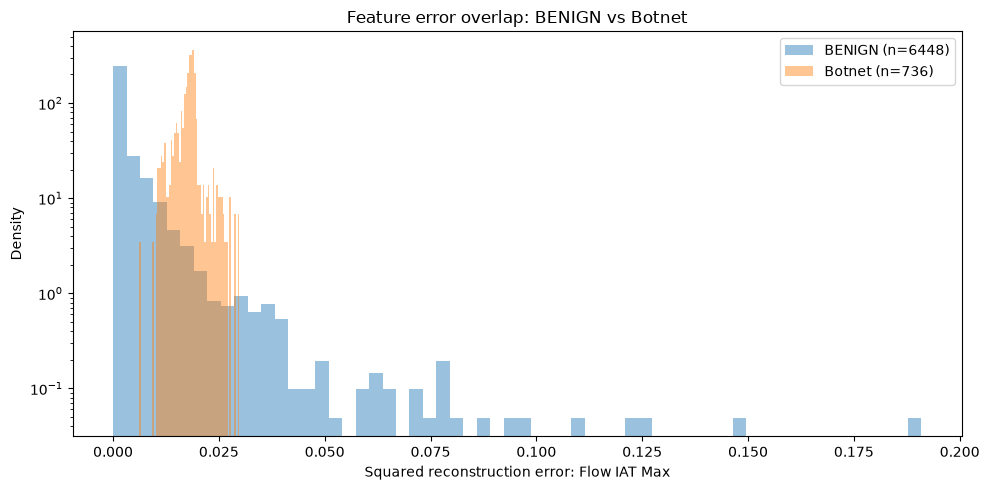

These are exploratory test-set comparisons. Fit any new score weights and thresholds on training/validation data only; use a new untouched test split for final claims.


In [28]:
# Diagnostic comparison: average MSE vs top-k largest feature errors per flow.
# No test-based threshold selection. Scores below are exploratory only.
from sklearn.metrics import roc_auc_score

k_values = [1, 3, 5, 10]
score_methods = {"Mean reconstruction MSE": feature_errors.mean(axis=1)}
for k in k_values:
    k = min(k, feature_errors.shape[1])
    score_methods[f"Top-{k} feature MSE"] = np.partition(feature_errors, -k, axis=1)[:, -k:].mean(axis=1)

comparison_rows = []
for attack in classes[1:]:
    mask = np.isin(labels, ["BENIGN", attack])
    if (labels == attack).sum() == 0:
        continue
    truth = (labels[mask] == attack).astype(int)
    for name, score in score_methods.items():
        comparison_rows.append({"Attack": attack, "Score method": name,
                                "ROC-AUC (diagnostic)": roc_auc_score(truth, score[mask])})
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.pivot(index="Score method", columns="Attack", values="ROC-AUC (diagnostic)").round(4))
comparison_df.to_csv(RESULTS_DIR / "v15_topk_score_comparison.csv", index=False)

# Distribution of feature errors for best *descriptive* Botnet feature.
# This plot is for understanding held-out results, not choosing model features.
bot_rows = feature_summary[feature_summary["Attack"] == "Botnet"]
if len(bot_rows):
    feature = bot_rows.sort_values("Single-feature ROC-AUC", ascending=False).iloc[0]["Feature"]
    j = feature_names.index(feature)
    fig, ax = plt.subplots(figsize=(10, 5))
    for cls in ["BENIGN", "Botnet"]:
        scores = feature_errors[labels == cls, j]
        ax.hist(scores, bins=60, density=True, alpha=0.45, label=f"{cls} (n={len(scores)})")
    ax.set(xlabel=f"Squared reconstruction error: {feature}", ylabel="Density",
           title="Feature error overlap: BENIGN vs Botnet")
    ax.set_yscale("log")
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "v15_botnet_feature_histogram.png", dpi=160)
    plt.show()
print("These are exploratory test-set comparisons. Fit any new score weights and thresholds on training/validation data only; use a new untouched test split for final claims.")